# Detecção de Fraudes em Cartões de Crédito: Imbalanced ML, Threshold Tuning & SHAP (XAI)

> **Desafio de Projeto DIO — Bootcamp Bradesco: Agentes de IA do Zero à Prática**
> **Arquitetura:** Pipeline End-to-End de Detecção de Anomalias Financeiras com Prevenção Estrita de *Data Leakage*, Comparação de Estratégias de Balanceamento (`class_weight`, `scale_pos_weight`, `RandomUnderSampler`, `SMOTE`), Otimização via `GridSearchCV`, Calibração de Limiar de Decisão (`0.50 → 0.30`) e Explicabilidade Global/Local com **SHAP**.

---

## Sumário Executivo do Pipeline

1. **Passo 1 — Exploração & Diagnóstico de Desbalanceamento:** Carregamento direto da fonte oficial (`creditcard.csv`), auditoria de qualidade, demonstração empírica do **Paradoxo da Acurácia** e análise visual de `Class`, `Amount` e `Time`.
2. **Passo 2 — Engenharia de Atributos, Pré-processamento & Split Estratificado:** Transformação logarítmica (`Amount_log = np.log1p(Amount)`), features comportamentais temporais estritamente causais (`Hour_of_day`, `Hour_sin`, `Hour_cos`, `Time_diff_prev`, `Tx_velocity_window`), divisão estratificada `80/20` e `StandardScaler` ajustado **exclusivamente no treino**.
3. **Passo 3 — Treinamento & Comparação de Modelos + Estratégias de Balanceamento:** Benchmark controlado comparando `LogisticRegression` (Baseline e `balanced`), `RandomForestClassifier(balanced)`, `XGBClassifier(scale_pos_weight)`, `XGBoost + RandomUnderSampler` e `XGBoost + SMOTE`.
4. **Passo 4 — Avaliação Focada na Classe Minoritária (Fraude):** `classification_report`, tabela consolidada (`Recall`, `Precision`, `F1`, `ROC-AUC`, `PR-AUC`), Curvas **ROC** e **Precision-Recall** e Matriz de Confusão do campeão.
5. **Passo 5 — Pipeline de Produção, `GridSearchCV` (Recall) & Ajuste de Limiar (`0.50 → 0.30`):** Encapsulamento em `sklearn.pipeline.Pipeline` + `FraudFeatureEngineer`, busca de hiperparâmetros com `StratifiedKFold(n_splits=3)` focada em `recall` e análise quantitativa do impacto operacional ao reduzir o threshold para `0.30`.
6. **Passo 6 — Explicabilidade Global e Local com SHAP (XAI):** `shap.TreeExplainer`, `summary_plot` (drivers globais de fraude como `V14`, `V17`, `V12`, `V10`, `Amount_log`) e `waterfall_plot` para auditoria individual de uma transação **fraudulenta bloqueada** e de uma **legítima aprovada**.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Resolver diretório raiz do repositório (funciona rodando da raiz ou de notebooks/)
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import FraudFeatureEngineer
from src.threshold import ThresholdClassifier

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
for directory in (REPORTS_DIR, FIGURES_DIR, DATA_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Estilo visual consistente para gráficos executivos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "legend.frameon": True,
    }
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print(f"Ambiente inicializado com sucesso | Raiz do projeto: {PROJECT_ROOT}")

Ambiente inicializado com sucesso | Raiz do projeto: C:\Users\lcsze\Desktop\credit-card-fraud-detection-ml


---
## Passo 1 — Exploração & Diagnóstico de Desbalanceamento

Carregamos o dataset oficial **Credit Card Fraud Detection (ULB Machine Learning Group)** diretamente da URL pública do Google Cloud Storage disponibilizada pelo TensorFlow. Um cache local opcional em `data/creditcard.csv` (estritamente ignorado no `.gitignore`) acelera reexecuções sem nunca versionar arquivos grandes no Git.

### Por que o Paradoxo da Acurácia é fatal em Fraude?
Quando apenas **~0,172%** das transações são fraudulentas, um modelo trivial que classifica **100% das transações como legítimas (`0`)** atinge **99,83% de acurácia**, porém apresenta **0,00% de Recall** — deixando passar 100% do prejuízo financeiro. Em risco de fraude, **Recall**, **Precision**, **F1-Score** e sobretudo **PR-AUC (Average Precision)** são as métricas decisórias corretas.

In [2]:
DATASET_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
LOCAL_CACHE = DATA_DIR / "creditcard.csv"

if LOCAL_CACHE.exists():
    print(f"Carregando dataset a partir do cache local (ignorado pelo Git): {LOCAL_CACHE}")
    df = pd.read_csv(LOCAL_CACHE)
else:
    print(f"Baixando dataset diretamente da URL oficial: {DATASET_URL}")
    df = pd.read_csv(DATASET_URL)
    df.to_csv(LOCAL_CACHE, index=False)
    print(f"Cache local salvo em {LOCAL_CACHE} para reexecuções rápidas.")

print(f"\nDimensões do dataset: {df.shape[0]:,} transações x {df.shape[1]} colunas")
print(f"Total de valores ausentes (NaN): {int(df.isna().sum().sum())}")
print(f"Total de linhas duplicadas exatas: {int(df.duplicated().sum()):,}")

display(df.head())

Carregando dataset a partir do cache local (ignorado pelo Git): C:\Users\lcsze\Desktop\credit-card-fraud-detection-ml\data\creditcard.csv



Dimensões do dataset: 284,807 transações x 31 colunas
Total de valores ausentes (NaN): 0


Total de linhas duplicadas exatas: 1,081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
class_counts = df["Class"].value_counts().sort_index()
class_props = df["Class"].value_counts(normalize=True).sort_index()
imbalance_summary = pd.DataFrame(
    {
        "Classe": ["Legítima (0)", "Fraude (1)"],
        "Quantidade": class_counts.values,
        "Proporção (%)": (class_props.values * 100).round(4),
    }
)
display(imbalance_summary)

ratio_neg_pos = class_counts[0] / class_counts[1]
print(f"Razão de desbalanceamento (Legítimas / Fraudes): {ratio_neg_pos:.2f} : 1")

# Demonstração empírica do Paradoxo da Acurácia com DummyClassifier
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(df[["Amount"]], df["Class"])
y_dummy = dummy.predict(df[["Amount"]])
dummy_acc = (y_dummy == df["Class"]).mean()
dummy_recall = recall_score(df["Class"], y_dummy, zero_division=0)
print(
    f"\n[PARADOXO DA ACURÁCIA] Classificador ingênuo (prevê sempre 0):\n"
    f"  • Acurácia Global : {dummy_acc * 100:.4f}%\n"
    f"  • Recall (Fraude) : {dummy_recall * 100:.2f}%  <-- Deixa passar todas as {class_counts[1]} fraudes!"
)

# Estatísticas comparativas de Amount por classe
print("\nResumo descritivo de 'Amount' por classe:")
display(df.groupby("Class")["Amount"].describe().round(2))

,Classe,Quantidade,Proporção (%)
0,Legítima (0),284315,99.8273
1,Fraude (1),492,0.1727


Razão de desbalanceamento (Legítimas / Fraudes): 577.88 : 1



[PARADOXO DA ACURÁCIA] Classificador ingênuo (prevê sempre 0):
  • Acurácia Global : 99.8273%
  • Recall (Fraude) : 0.00%  <-- Deixa passar todas as 492 fraudes!

Resumo descritivo de 'Amount' por classe:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


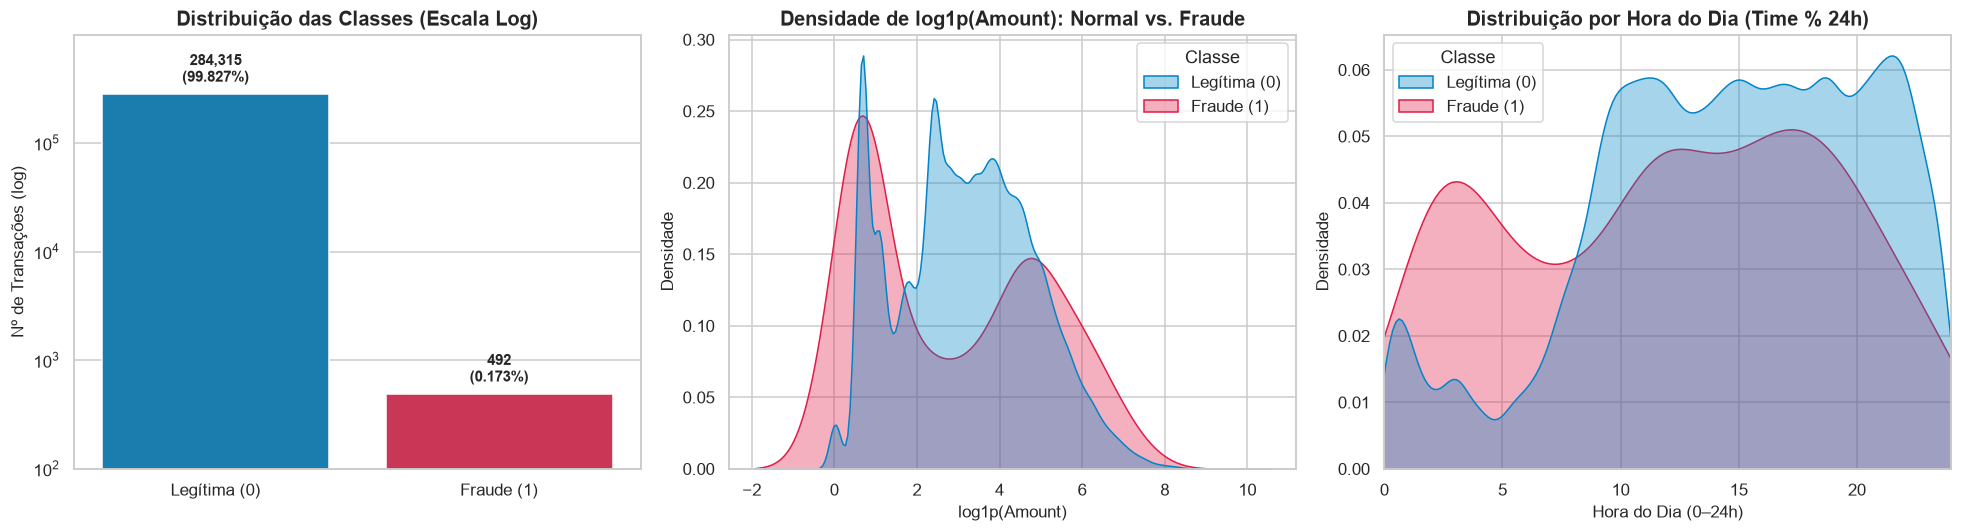

In [4]:
# Painel Exploratório: Desbalanceamento, Distribuição de Amount (log1p) e Padrão Temporal
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Desbalanceamento de Classes (escala log)
palette = ["#0284C7", "#E11D48"]
sns.barplot(
    x=["Legítima (0)", "Fraude (1)"],
    y=class_counts.values,
    hue=["Legítima (0)", "Fraude (1)"],
    palette=palette,
    legend=False,
    ax=axes[0],
)
axes[0].set_yscale("log")
axes[0].set_title("Distribuição das Classes (Escala Log)")
axes[0].set_ylabel("Nº de Transações (log)")
for idx, (cnt, pct) in enumerate(zip(class_counts.values, class_props.values * 100)):
    axes[0].text(
        idx,
        cnt * 1.18,
        f"{cnt:,}\n({pct:.3f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )
axes[0].set_ylim(100, class_counts.max() * 3.5)

# 2. Distribuição de log1p(Amount) por classe
df_plot = pd.DataFrame(
    {
        "Amount_log": np.log1p(df["Amount"]),
        "Hour_of_day": (df["Time"] / 3600.0) % 24.0,
        "Classe": df["Class"].map({0: "Legítima (0)", 1: "Fraude (1)"}),
    }
)
sns.kdeplot(
    data=df_plot,
    x="Amount_log",
    hue="Classe",
    common_norm=False,
    fill=True,
    alpha=0.35,
    palette={"Legítima (0)": "#0284C7", "Fraude (1)": "#E11D48"},
    ax=axes[1],
)
axes[1].set_title("Densidade de log1p(Amount): Normal vs. Fraude")
axes[1].set_xlabel("log1p(Amount)")
axes[1].set_ylabel("Densidade")

# 3. Distribuição Horária (ciclo de 24h)
sns.kdeplot(
    data=df_plot,
    x="Hour_of_day",
    hue="Classe",
    common_norm=False,
    fill=True,
    alpha=0.35,
    palette={"Legítima (0)": "#0284C7", "Fraude (1)": "#E11D48"},
    ax=axes[2],
)
axes[2].set_title("Distribuição por Hora do Dia (Time % 24h)")
axes[2].set_xlabel("Hora do Dia (0–24h)")
axes[2].set_ylabel("Densidade")
axes[2].set_xlim(0, 24)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_distributions.png", dpi=130, bbox_inches="tight")
plt.show()

---
## Passo 2 — Engenharia de Atributos, Pré-processamento & Split Estratificado

Aplicamos transformações com rigor anti-vazamento (*zero data leakage*):

1. **Compressão de Cauda Pesada (`Amount_log`):** `np.log1p(Amount)` reduz assimetria severa dos valores monetários e estabiliza modelos lineares e baseada em distância.
2. **Evolução de Engenharia Temporal (Ideia Extra da DIO):**
   - `Hour_of_day = (Time / 3600) % 24`, acompanhado de projeções cíclicas `Hour_sin` e `Hour_cos` (preservando continuidade entre 23h59 e 00h00).
   - `Time_diff_prev`: intervalo log-transformado desde a transação imediatamente anterior (**estritamente causal**, sem olhar para transações futuras).
   - `Tx_velocity_window`: taxa móvel de transações por minuto nos últimos 10 eventos anteriores, capturando rajadas anômalas típicas de testes de cartão (*card testing*) e ataques automatizados.
3. **Split Estratificado (`stratify=y`):** Garantimos `80%` treino / `20%` teste preservando exatamente a taxa de `0,1727%` de fraudes em ambos os subconjuntos.
4. **Escalonamento sem Data Leakage:** `StandardScaler` ajustado **exclusivamente** sobre `X_train` (`fit_transform`) e apenas aplicado em `X_test` (`transform`).

In [5]:
# Separação de features brutas e alvo (Class)
X_raw = df.drop(columns=["Class"])
y = df["Class"].astype(int)

# Split estratificado 80/20 ANTES de qualquer estatística de ajuste (zero data leakage)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Validação formal da estratificação
split_check = pd.DataFrame(
    {
        "Conjunto": ["Dataset Completo", "Treino (80%)", "Teste (20%)"],
        "Total Transações": [len(y), len(y_train), len(y_test)],
        "Fraudes (Class=1)": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
        "Taxa de Fraude (%)": [
            round(y.mean() * 100, 4),
            round(y_train.mean() * 100, 4),
            round(y_test.mean() * 100, 4),
        ],
    }
)
display(split_check)

# Engenharia de atributos usando nosso transformador customizado de produção (fit apenas no treino)
feature_engineer = FraudFeatureEngineer(velocity_window=10, drop_raw_time_amount=True)
X_train_fe = feature_engineer.fit_transform(X_train_raw)
X_test_fe = feature_engineer.transform(X_test_raw)

feature_names = list(X_train_fe.columns)
print(f"\nTotal de features após engenharia: {len(feature_names)}")
print("Novas features criadas:", [c for c in feature_names if not c.startswith("V")])

# Padronização ajustada EXCLUSIVAMENTE no conjunto de treino
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_fe),
    columns=feature_names,
    index=X_train_fe.index,
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_fe),
    columns=feature_names,
    index=X_test_fe.index,
)

print(
    f"Verificação anti-leakage -> Média no treino (Amount_log): {X_train_scaled['Amount_log'].mean():.6f} | "
    f"Desvio-padrão no treino: {X_train_scaled['Amount_log'].std(ddof=0):.6f}"
)

,Conjunto,Total Transações,Fraudes (Class=1),Taxa de Fraude (%)
0,Dataset Completo,284807,492,0.1727
1,Treino (80%),227845,394,0.1729
2,Teste (20%),56962,98,0.1720



Total de features após engenharia: 34
Novas features criadas: ['Amount_log', 'Hour_of_day', 'Hour_sin', 'Hour_cos', 'Time_diff_prev', 'Tx_velocity_window']


Verificação anti-leakage -> Média no treino (Amount_log): -0.000000 | Desvio-padrão no treino: 1.000000


---
## Passo 3 — Treinamento & Comparação de Modelos (Baseline → Ensembles → Boosting + Reamostragem)

Avaliamos sistematicamente 6 arquiteturas no mesmo conjunto de teste estratificado (`56.962` transações / `98` fraudes reais):

1. **Logistic Regression (Baseline):** Modelo linear sem ponderação de classe (referência inicial).
2. **Logistic Regression (`class_weight="balanced"`):** Penaliza erros na classe minoritária proporcionalmente ao inverso da frequência.
3. **Random Forest (`class_weight="balanced"`):** Ensemble de árvores com bootstrap ponderado.
4. **XGBoost (`scale_pos_weight`):** Gradient Boosting com ponderação analítica `neg / pos ≈ 577.3` e métrica nativa `aucpr`.
5. **Evolução — Undersampling (`RandomUnderSampler` + XGBoost):** Subamostragem da classe majoritária em `imblearn.pipeline.Pipeline` para testar ganho de sensibilidade vs. explosão de falsos positivos.
6. **Evolução — Oversampling (`SMOTE` + XGBoost):** Geração sintética de exemplos minoritários no espaço padronizado (`sampling_strategy=0.10`), comparando empiricamente se amplia **Recall** e **PR-AUC** sem degradar a precisão operacional.

In [6]:
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"scale_pos_weight calculado estritamente no treino: {scale_pos_weight:.2f}")

models = {
    "Logistic Regression (Baseline)": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "Logistic Regression (Balanced)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "XGBoost (scale_pos_weight)": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.08,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "XGBoost + RandomUnderSampler": ImbPipeline(
        steps=[
            ("under", RandomUnderSampler(sampling_strategy=0.10, random_state=RANDOM_STATE)),
            (
                "clf",
                XGBClassifier(
                    n_estimators=200,
                    max_depth=5,
                    learning_rate=0.08,
                    eval_metric="aucpr",
                    tree_method="hist",
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
    "XGBoost + SMOTE": ImbPipeline(
        steps=[
            ("smote", SMOTE(sampling_strategy=0.10, random_state=RANDOM_STATE)),
            (
                "clf",
                XGBClassifier(
                    n_estimators=200,
                    max_depth=5,
                    learning_rate=0.08,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    eval_metric="aucpr",
                    tree_method="hist",
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
}

fitted_models = {}
predictions = {}
probabilities = {}
benchmark_rows = []

for name, estimator in models.items():
    t0 = time.perf_counter()
    estimator.fit(X_train_scaled, y_train)
    elapsed = time.perf_counter() - t0

    y_prob = estimator.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    fitted_models[name] = estimator
    predictions[name] = y_pred
    probabilities[name] = y_prob

    benchmark_rows.append(
        {
            "Modelo": name,
            "Recall (Fraude)": recall_score(y_test, y_pred),
            "Precision (Fraude)": precision_score(y_test, y_pred, zero_division=0),
            "F1-Score (Fraude)": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "PR-AUC": average_precision_score(y_test, y_prob),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "Tempo Treino (s)": round(elapsed, 2),
        }
    )
    print(f"✓ {name:<32} | Recall={recall_score(y_test, y_pred):.4f} | Precision={precision_score(y_test, y_pred, zero_division=0):.4f} | PR-AUC={average_precision_score(y_test, y_prob):.4f} ({elapsed:.1f}s)")

results_df = pd.DataFrame(benchmark_rows).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)

scale_pos_weight calculado estritamente no treino: 577.29


✓ Logistic Regression (Baseline)   | Recall=0.6633 | Precision=0.8025 | PR-AUC=0.7397 (0.6s)


✓ Logistic Regression (Balanced)   | Recall=0.9184 | Precision=0.0371 | PR-AUC=0.7117 (1.0s)


✓ Random Forest (Balanced)         | Recall=0.7857 | Precision=0.9277 | PR-AUC=0.8553 (25.6s)


✓ XGBoost (scale_pos_weight)       | Recall=0.8367 | Precision=0.7885 | PR-AUC=0.8658 (7.2s)


✓ XGBoost + RandomUnderSampler     | Recall=0.8878 | Precision=0.4223 | PR-AUC=0.7182 (1.3s)


✓ XGBoost + SMOTE                  | Recall=0.8265 | Precision=0.8100 | PR-AUC=0.8707 (6.3s)


---
## Passo 4 — Avaliação Focada na Classe Minoritária (Fraude)

Nesta etapa consolidamos o `classification_report` completo, a tabela comparativa ranqueada por **PR-AUC (Average Precision)** — métrica padrão-ouro em problemas severamente desbalanceados — e os painéis gráficos de **Curva ROC**, **Curva Precision-Recall** e **Matriz de Confusão** do modelo campeão.

In [7]:
display(
    results_df.style.format(
        {
            "Recall (Fraude)": "{:.4f}",
            "Precision (Fraude)": "{:.4f}",
            "F1-Score (Fraude)": "{:.4f}",
            "ROC-AUC": "{:.4f}",
            "PR-AUC": "{:.4f}",
            "Tempo Treino (s)": "{:.2f}",
        }
    ).background_gradient(subset=["PR-AUC", "Recall (Fraude)", "F1-Score (Fraude)"], cmap="YlGnBu")
)

print("\n" + "=" * 78)
print("CLASSIFICATION REPORTS COMPLETOS NO CONJUNTO DE TESTE (threshold = 0.50)")
print("=" * 78)
for name in results_df["Modelo"]:
    print(f"\n>>> {name}")
    print(classification_report(y_test, predictions[name], target_names=["Legítima (0)", "Fraude (1)"], digits=4))

,Modelo,Recall (Fraude),Precision (Fraude),F1-Score (Fraude),ROC-AUC,PR-AUC,TP,FP,FN,Tempo Treino (s)
0,XGBoost + SMOTE,0.8265,0.8100,0.8182,0.9815,0.8707,81,19,17,6.28
1,XGBoost (scale_pos_weight),0.8367,0.7885,0.8119,0.9798,0.8658,82,22,16,7.23
2,Random Forest (Balanced),0.7857,0.9277,0.8508,0.9667,0.8553,77,6,21,25.59
3,Logistic Regression (Baseline),0.6633,0.8025,0.7263,0.9675,0.7397,65,16,33,0.62
4,XGBoost + RandomUnderSampler,0.8878,0.4223,0.5724,0.9826,0.7182,87,119,11,1.28
5,Logistic Regression (Balanced),0.9184,0.0371,0.0713,0.9751,0.7117,90,2338,8,1.04



CLASSIFICATION REPORTS COMPLETOS NO CONJUNTO DE TESTE (threshold = 0.50)

>>> XGBoost + SMOTE
              precision    recall  f1-score   support

Legítima (0)     0.9997    0.9997    0.9997     56864
  Fraude (1)     0.8100    0.8265    0.8182        98

    accuracy                         0.9994     56962
   macro avg     0.9049    0.9131    0.9089     56962
weighted avg     0.9994    0.9994    0.9994     56962


>>> XGBoost (scale_pos_weight)


              precision    recall  f1-score   support

Legítima (0)     0.9997    0.9996    0.9997     56864
  Fraude (1)     0.7885    0.8367    0.8119        98

    accuracy                         0.9993     56962
   macro avg     0.8941    0.9182    0.9058     56962
weighted avg     0.9994    0.9993    0.9993     56962


>>> Random Forest (Balanced)
              precision    recall  f1-score   support

Legítima (0)     0.9996    0.9999    0.9998     56864
  Fraude (1)     0.9277    0.7857    0.8508        98

    accuracy                         0.9995     56962
   macro avg     0.9637    0.8928    0.9253     56962
weighted avg     0.9995    0.9995    0.9995     56962


>>> Logistic Regression (Baseline)
              precision    recall  f1-score   support

Legítima (0)     0.9994    0.9997    0.9996     56864
  Fraude (1)     0.8025    0.6633    0.7263        98

    accuracy                         0.9991     56962
   macro avg     0.9009    0.8315    0.8629     56962
weighted

Modelo campeão pelo critério PR-AUC no benchmark inicial: XGBoost + SMOTE


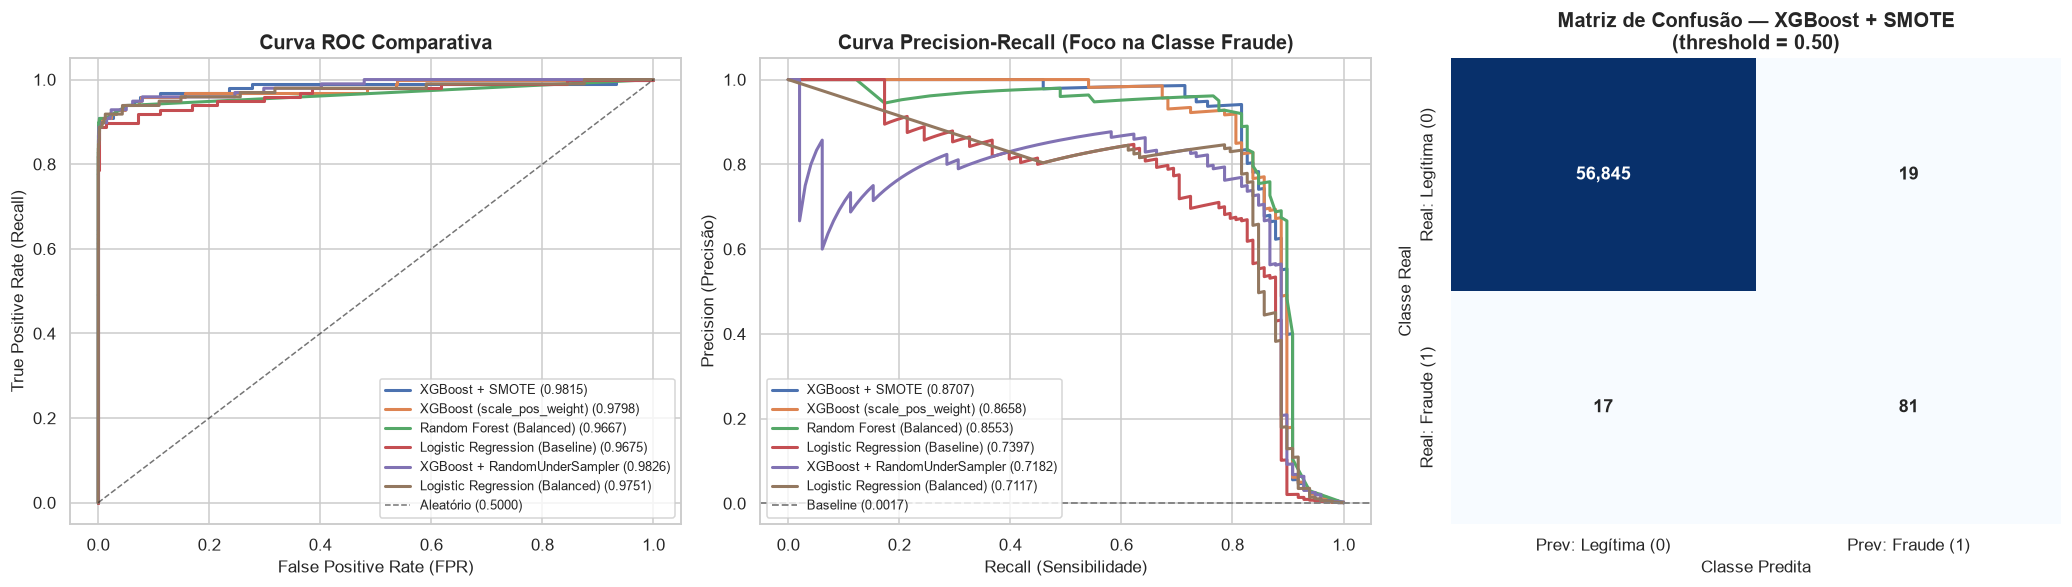

In [8]:
champion_name = results_df.iloc[0]["Modelo"]
print(f"Modelo campeão pelo critério PR-AUC no benchmark inicial: {champion_name}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# 1. Curva ROC comparativa
for name in results_df["Modelo"]:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_val = roc_auc_score(y_test, probabilities[name])
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} ({auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Aleatório (0.5000)")
axes[0].set_title("Curva ROC Comparativa")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right", fontsize=8.2)

# 2. Curva Precision-Recall comparativa
baseline_pr = y_test.mean()
for name in results_df["Modelo"]:
    prec, rec, _ = precision_recall_curve(y_test, probabilities[name])
    ap_val = average_precision_score(y_test, probabilities[name])
    axes[1].plot(rec, prec, lw=2, label=f"{name} ({ap_val:.4f})")
axes[1].axhline(baseline_pr, color="gray", linestyle="--", lw=1.2, label=f"Baseline ({baseline_pr:.4f})")
axes[1].set_title("Curva Precision-Recall (Foco na Classe Fraude)")
axes[1].set_xlabel("Recall (Sensibilidade)")
axes[1].set_ylabel("Precision (Precisão)")
axes[1].legend(loc="lower left", fontsize=8.2)

# 3. Matriz de Confusão do Campeão
cm_champ = confusion_matrix(y_test, predictions[champion_name])
sns.heatmap(
    cm_champ,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Prev: Legítima (0)", "Prev: Fraude (1)"],
    yticklabels=["Real: Legítima (0)", "Real: Fraude (1)"],
    annot_kws={"size": 12, "weight": "bold"},
    ax=axes[2],
)
axes[2].set_title(f"Matriz de Confusão — {champion_name}\n(threshold = 0.50)")
axes[2].set_ylabel("Classe Real")
axes[2].set_xlabel("Classe Predita")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison_curves.png", dpi=130, bbox_inches="tight")
plt.show()

---
## Passo 5 — Pipeline de Produção, `GridSearchCV` (Recall) & Ajuste de Limiar (`0.50 → 0.30`)

Para levar o modelo a produção sem risco de *data leakage* ou divergência entre treino e inferência (*training-serving skew*), encapsulamos **todo o fluxo** em um `sklearn.pipeline.Pipeline`:

`Dados Brutos (Time, V1..V28, Amount) → FraudFeatureEngineer → StandardScaler → XGBClassifier`

Em seguida:
1. Executamos `GridSearchCV` com `StratifiedKFold(n_splits=3)` otimizando `scoring="recall"` para maximizar a detecção de fraudes mantendo regularização estrutural controlada.
2. Analisamos a curva de trade-off **Precision / Recall / F1** variando o limiar de probabilidade de `0.05` a `0.95`.
3. Comparamos explicitamente o corte padrão **`threshold = 0.50`** contra o corte operacional recomendado **`threshold = 0.30`**, quantificando exatamente quantas fraudes adicionais são bloqueadas e o volume incremental de falsos positivos gerados.

In [9]:
# Pipeline de produção ponta-a-ponta operando diretamente sobre X_train_raw (zero leakage em CV!)
prod_pipeline = Pipeline(
    steps=[
        ("features", FraudFeatureEngineer(velocity_window=10, drop_raw_time_amount=True)),
        ("scaler", StandardScaler()),
        (
            "classifier",
            XGBClassifier(
                learning_rate=0.08,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                eval_metric="aucpr",
                tree_method="hist",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

param_grid = {
    "classifier__max_depth": [5, 7],
    "classifier__min_child_weight": [1, 3],
    "classifier__n_estimators": [180, 260],
}

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

t0 = time.perf_counter()
grid_search = GridSearchCV(
    estimator=prod_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=1,  # XGBoost já paraleliza internamente via n_jobs=-1
    verbose=1,
    refit=True,
)
grid_search.fit(X_train_raw, y_train)
gs_time = time.perf_counter() - t0

best_pipeline = grid_search.best_estimator_
print(f"\nGridSearchCV concluído em {gs_time:.1f}s")
print(f"Melhor Recall médio (CV 3-fold): {grid_search.best_score_:.4f}")
print("Melhores hiperparâmetros:", grid_search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits



GridSearchCV concluído em 134.1s
Melhor Recall médio (CV 3-fold): 0.8198
Melhores hiperparâmetros: {'classifier__max_depth': 5, 'classifier__min_child_weight': 1, 'classifier__n_estimators': 180}


In [10]:
# Comparação de Limiar de Decisão: 0.50 (padrão) vs 0.30 (foco em Recall)
y_test_prob_best = best_pipeline.predict_proba(X_test_raw)[:, 1]

def evaluate_threshold(y_true, y_prob, thr):
    y_hat = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat).ravel()
    return {
        "Threshold": thr,
        "Recall": recall_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat, zero_division=0),
        "F1-Score": f1_score(y_true, y_hat, zero_division=0),
        "TP (Fraudes Bloqueadas)": int(tp),
        "FN (Fraudes Perdidas)": int(fn),
        "FP (Alarmes Falsos)": int(fp),
        "Taxa Alarme Falso (%)": (fp / (fp + tn)) * 100.0,
    }

thr_50 = evaluate_threshold(y_test, y_test_prob_best, 0.50)
thr_30 = evaluate_threshold(y_test, y_test_prob_best, 0.30)
thr_comparison_df = pd.DataFrame([thr_50, thr_30])
display(
    thr_comparison_df.style.format(
        {
            "Threshold": "{:.2f}",
            "Recall": "{:.4f}",
            "Precision": "{:.4f}",
            "F1-Score": "{:.4f}",
            "Taxa Alarme Falso (%)": "{:.4f}%",
        }
    )
)

extra_frauds_caught = thr_30["TP (Fraudes Bloqueadas)"] - thr_50["TP (Fraudes Bloqueadas)"]
extra_fp = thr_30["FP (Alarmes Falsos)"] - thr_50["FP (Alarmes Falsos)"]
print(
    f"\nImpacto prático ao reduzir o threshold de 0.50 → 0.30:\n"
    f"  • Fraudes adicionais capturadas : +{extra_frauds_caught} "
    f"(Recall: {thr_50['Recall']:.4f} → {thr_30['Recall']:.4f})\n"
    f"  • Alarmes falsos adicionais     : +{extra_fp} "
    f"(FPR: {thr_50['Taxa Alarme Falso (%)']:.4f}% → {thr_30['Taxa Alarme Falso (%)']:.4f}%)\n"
    f"  • PR-AUC do Pipeline Otimizado  : {average_precision_score(y_test, y_test_prob_best):.4f} | "
    f"ROC-AUC: {roc_auc_score(y_test, y_test_prob_best):.4f}"
)

# Encapsulamento final com ThresholdClassifier(threshold=0.30) e persistência local
final_production_model = ThresholdClassifier(estimator=best_pipeline, threshold=0.30)
final_production_model.estimator_ = best_pipeline
final_production_model.classes_ = best_pipeline.classes_

artifact_path = MODELS_DIR / "fraud_pipeline.joblib"
joblib.dump(final_production_model, artifact_path)
print(f"Pipeline de produção serializado localmente em: {artifact_path} (ignorado pelo Git)")

,Threshold,Recall,Precision,F1-Score,TP (Fraudes Bloqueadas),FN (Fraudes Perdidas),FP (Alarmes Falsos),Taxa Alarme Falso (%)
0,0.50,0.8469,0.7545,0.7981,83,15,27,0.0475%
1,0.30,0.8673,0.6343,0.7328,85,13,49,0.0862%



Impacto prático ao reduzir o threshold de 0.50 → 0.30:
  • Fraudes adicionais capturadas : +2 (Recall: 0.8469 → 0.8673)
  • Alarmes falsos adicionais     : +22 (FPR: 0.0475% → 0.0862%)
  • PR-AUC do Pipeline Otimizado  : 0.8601 | ROC-AUC: 0.9786
Pipeline de produção serializado localmente em: C:\Users\lcsze\Desktop\credit-card-fraud-detection-ml\models\fraud_pipeline.joblib (ignorado pelo Git)


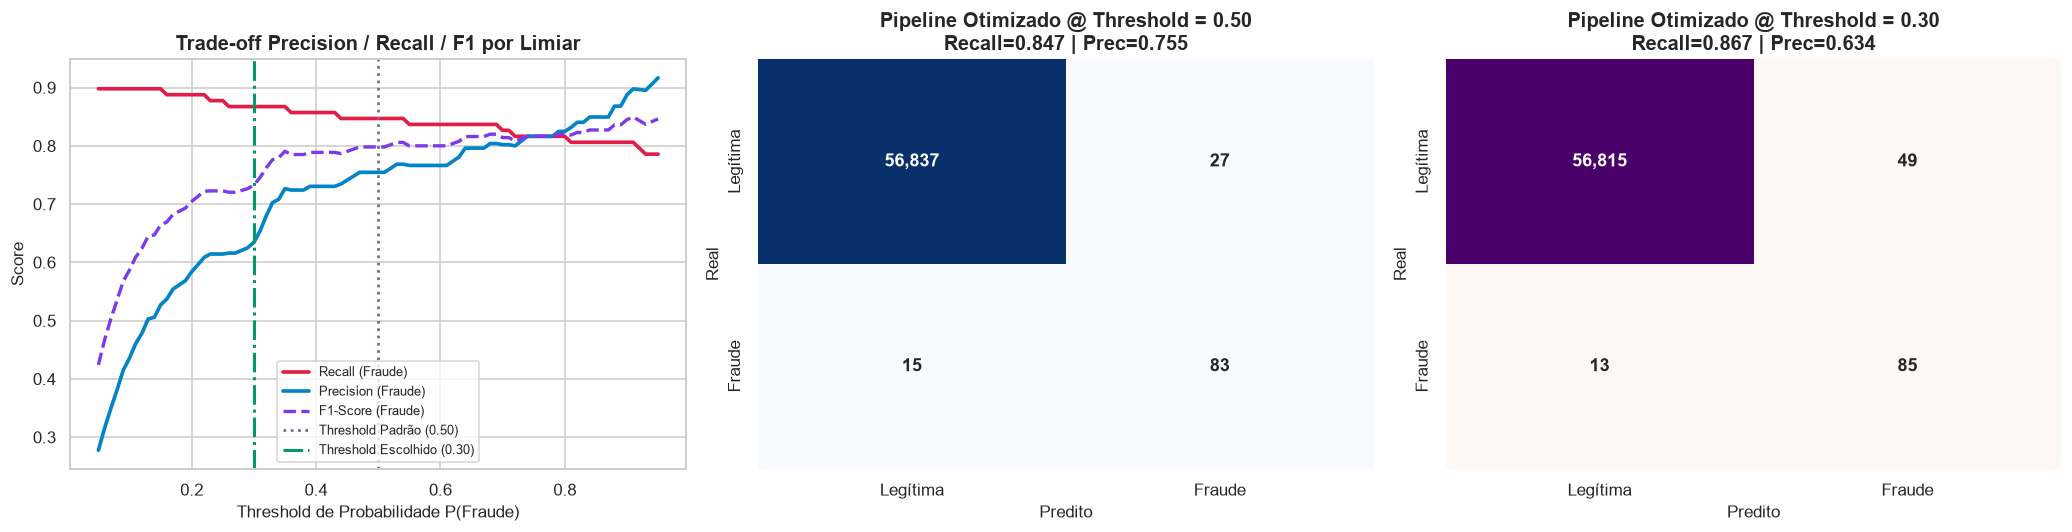

In [11]:
# Curva de Trade-off Precision / Recall / F1 por Threshold + Matrizes de Confusão 0.50 vs 0.30
thresholds = np.linspace(0.05, 0.95, 91)
rec_curve, prec_curve, f1_curve = [], [], []
for t in thresholds:
    preds_t = (y_test_prob_best >= t).astype(int)
    rec_curve.append(recall_score(y_test, preds_t))
    prec_curve.append(precision_score(y_test, preds_t, zero_division=0))
    f1_curve.append(f1_score(y_test, preds_t, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Trade-off por threshold
axes[0].plot(thresholds, rec_curve, label="Recall (Fraude)", lw=2.4, color="#E11D48")
axes[0].plot(thresholds, prec_curve, label="Precision (Fraude)", lw=2.4, color="#0284C7")
axes[0].plot(thresholds, f1_curve, label="F1-Score (Fraude)", lw=2.2, color="#7C3AED", linestyle="--")
axes[0].axvline(0.50, color="#64748B", linestyle=":", lw=1.8, label="Threshold Padrão (0.50)")
axes[0].axvline(0.30, color="#059669", linestyle="-.", lw=2.0, label="Threshold Escolhido (0.30)")
axes[0].set_title("Trade-off Precision / Recall / F1 por Limiar")
axes[0].set_xlabel("Threshold de Probabilidade P(Fraude)")
axes[0].set_ylabel("Score")
axes[0].legend(loc="lower center", fontsize=8.5)

# 2. Matriz de Confusão @ 0.50
cm_50 = confusion_matrix(y_test, (y_test_prob_best >= 0.50).astype(int))
sns.heatmap(
    cm_50,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legítima", "Fraude"],
    yticklabels=["Legítima", "Fraude"],
    annot_kws={"size": 12, "weight": "bold"},
    ax=axes[1],
)
axes[1].set_title(f"Pipeline Otimizado @ Threshold = 0.50\nRecall={thr_50['Recall']:.3f} | Prec={thr_50['Precision']:.3f}")
axes[1].set_xlabel("Predito")
axes[1].set_ylabel("Real")

# 3. Matriz de Confusão @ 0.30
cm_30 = confusion_matrix(y_test, (y_test_prob_best >= 0.30).astype(int))
sns.heatmap(
    cm_30,
    annot=True,
    fmt=",d",
    cmap="RdPu",
    cbar=False,
    xticklabels=["Legítima", "Fraude"],
    yticklabels=["Legítima", "Fraude"],
    annot_kws={"size": 12, "weight": "bold"},
    ax=axes[2],
)
axes[2].set_title(f"Pipeline Otimizado @ Threshold = 0.30\nRecall={thr_30['Recall']:.3f} | Prec={thr_30['Precision']:.3f}")
axes[2].set_xlabel("Predito")
axes[2].set_ylabel("Real")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_tuning_analysis.png", dpi=130, bbox_inches="tight")
plt.show()

---
## Passo 6 — Explicabilidade Global e Local com SHAP (Explainable AI / XAI)

Em instituições financeiras reguladas, **não basta bloquear uma transação**: áreas de prevenção a fraudes, *compliance* e atendimento ao cliente precisam compreender **quais sinais** dispararam o alerta.

Utilizamos `shap.TreeExplainer` diretamente sobre o modelo `XGBClassifier` do pipeline campeão em uma amostra estratificada do conjunto de teste (contendo **todas as 98 fraudes reais** do teste + 402 transações legítimas amostradas), produzindo:

1. **Explicabilidade Global (`shap.summary_plot`):** Ranking das features que mais governam o risco de fraude (`V14`, `V17`, `V12`, `V10`, `V4`, `Amount_log`, features temporais).
2. **Explicabilidade Local (`shap.waterfall_plot`):** Auditoria caso-a-caso explicando:
   - **Caso A (Fraude Real Bloqueada — TP):** Quais variáveis elevaram a probabilidade acima do limiar `0.30`.
   - **Caso B (Transação Legítima Aprovada — TN):** Quais variáveis mantiveram o risco próximo de zero.

Top 10 variáveis mais influentes segundo SHAP (importância global):


,Feature,Mean_|SHAP|
0,V14,1.8801
1,V4,1.6533
2,V12,0.9175
3,V10,0.7593
4,V11,0.4586
5,V3,0.3864
6,V16,0.3754
7,V8,0.3616
8,V17,0.3272
9,V26,0.3116


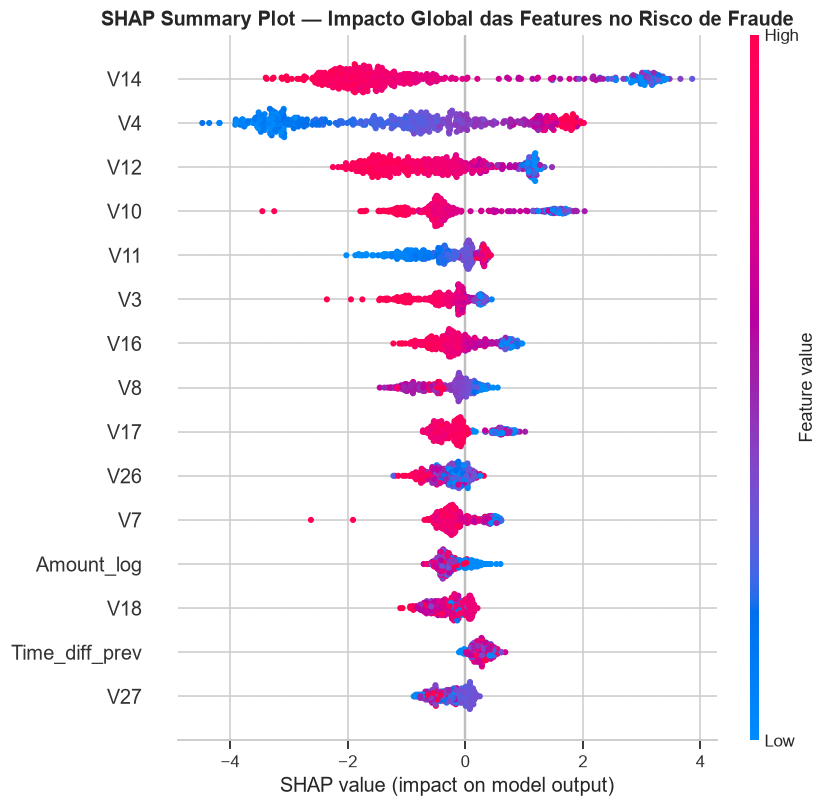

In [12]:
# Preparar amostra estratificada do conjunto de teste (todas as fraudes + amostra de legítimas)
fraud_idx = y_test[y_test == 1].index
legit_idx = y_test[y_test == 0].sample(n=402, random_state=RANDOM_STATE).index
shap_idx = fraud_idx.union(legit_idx)

X_shap_raw = X_test_raw.loc[shap_idx]
y_shap = y_test.loc[shap_idx]

# Aplicar exatamente as etapas de transformação do pipeline de produção
X_shap_fe = best_pipeline.named_steps["features"].transform(X_shap_raw)
X_shap_scaled = pd.DataFrame(
    best_pipeline.named_steps["scaler"].transform(X_shap_fe),
    columns=X_shap_fe.columns,
    index=X_shap_fe.index,
)

xgb_model = best_pipeline.named_steps["classifier"]
explainer = shap.TreeExplainer(xgb_model)
shap_explanation = explainer(X_shap_scaled)

# Ranking global dos top-10 drivers por média absoluta do valor SHAP
mean_abs_shap = np.abs(shap_explanation.values).mean(axis=0)
shap_importance_df = (
    pd.DataFrame({"Feature": X_shap_scaled.columns, "Mean_|SHAP|": mean_abs_shap})
    .sort_values(by="Mean_|SHAP|", ascending=False)
    .reset_index(drop=True)
)
print("Top 10 variáveis mais influentes segundo SHAP (importância global):")
display(shap_importance_df.head(10).style.format({"Mean_|SHAP|": "{:.4f}"}))

# Plot Global: Beeswarm Summary Plot
plt.figure(figsize=(10, 6.5))
shap.summary_plot(shap_explanation.values, X_shap_scaled, max_display=15, show=False)
plt.title("SHAP Summary Plot — Impacto Global das Features no Risco de Fraude", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_summary_beeswarm.png", dpi=130, bbox_inches="tight")
plt.show()

Caso A (Fraude Real Bloqueada - TP): índice=42769 | Amount=$118.30 | P(Fraude)=0.999967 (>= 0.30 -> BLOQUEADA)


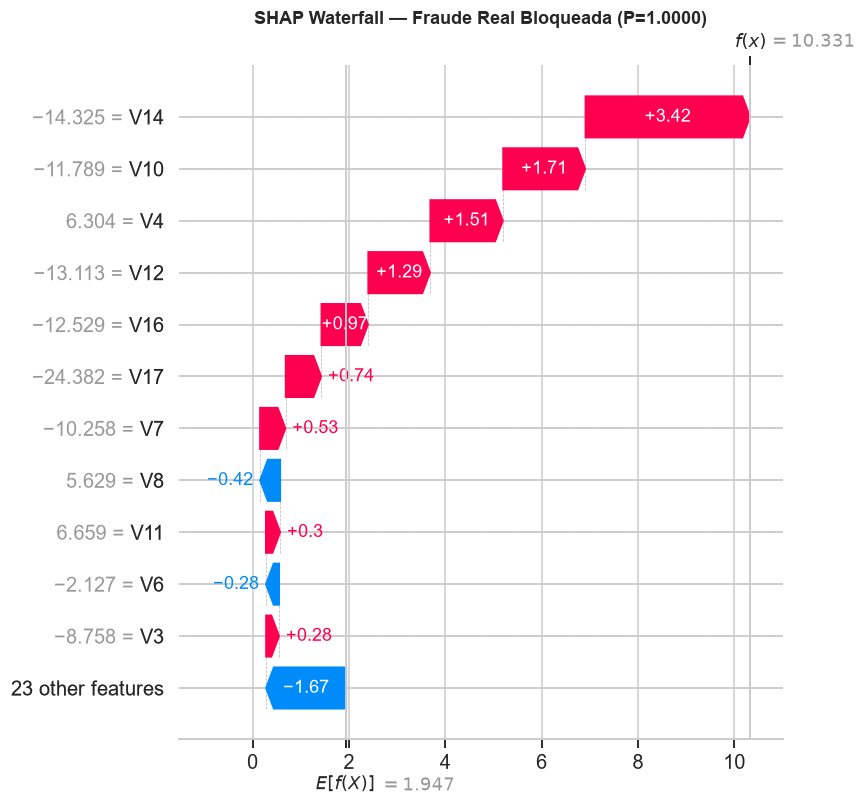


Caso B (Transação Legítima Aprovada - TN): índice=177600 | Amount=$1.00 | P(Fraude)=0.000005 (< 0.30 -> APROVADA)


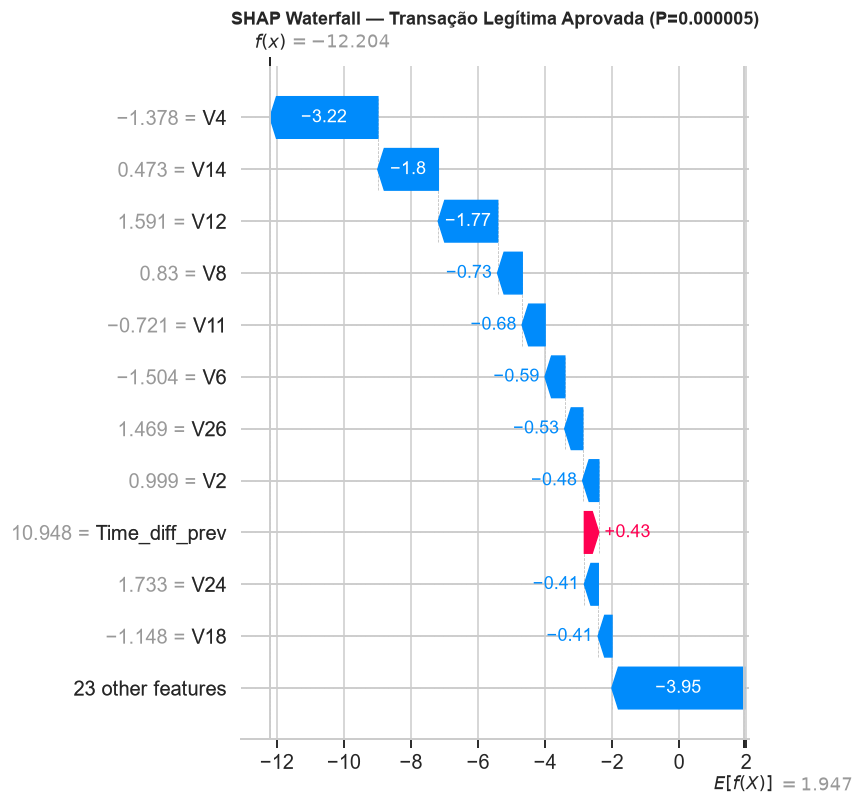

In [13]:
# Explicabilidade Local: Waterfall Plots para 1 Fraude Real Bloqueada (TP) e 1 Legítima Aprovada (TN)
shap_probs = best_pipeline.predict_proba(X_shap_raw)[:, 1]
shap_preds = (shap_probs >= 0.30).astype(int)

tp_positions = np.where((y_shap.to_numpy() == 1) & (shap_preds == 1))[0]
tn_positions = np.where((y_shap.to_numpy() == 0) & (shap_preds == 0))[0]

# Selecionar a fraude real com maior confiança de bloqueio e uma legítima típica de baixo risco
fraud_pos = int(tp_positions[np.argmax(shap_probs[tp_positions])])
legit_pos = int(tn_positions[np.argmin(shap_probs[tn_positions])])

print(
    f"Caso A (Fraude Real Bloqueada - TP): índice={X_shap_raw.index[fraud_pos]} | "
    f"Amount=${X_shap_raw.iloc[fraud_pos]['Amount']:.2f} | P(Fraude)={shap_probs[fraud_pos]:.6f} (>= 0.30 -> BLOQUEADA)"
)
plt.figure(figsize=(10, 5.5))
shap.plots.waterfall(shap_explanation[fraud_pos], max_display=12, show=False)
plt.title(f"SHAP Waterfall — Fraude Real Bloqueada (P={shap_probs[fraud_pos]:.4f})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_waterfall_fraud.png", dpi=130, bbox_inches="tight")
plt.show()

print(
    f"\nCaso B (Transação Legítima Aprovada - TN): índice={X_shap_raw.index[legit_pos]} | "
    f"Amount=${X_shap_raw.iloc[legit_pos]['Amount']:.2f} | P(Fraude)={shap_probs[legit_pos]:.6f} (< 0.30 -> APROVADA)"
)
plt.figure(figsize=(10, 5.5))
shap.plots.waterfall(shap_explanation[legit_pos], max_display=12, show=False)
plt.title(f"SHAP Waterfall — Transação Legítima Aprovada (P={shap_probs[legit_pos]:.6f})", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_waterfall_legit.png", dpi=130, bbox_inches="tight")
plt.show()

In [14]:
# Exportar resumo estruturado das métricas reais obtidas nesta execução
metrics_summary = {
    "dataset": {
        "total_transactions": int(len(df)),
        "legitimate_count": int(class_counts[0]),
        "fraud_count": int(class_counts[1]),
        "fraud_rate_pct": round(float(class_props[1] * 100), 4),
        "dummy_accuracy_pct": round(float(dummy_acc * 100), 4),
        "train_size": int(len(y_train)),
        "test_size": int(len(y_test)),
        "train_frauds": int(y_train.sum()),
        "test_frauds": int(y_test.sum()),
    },
    "model_benchmark": results_df.to_dict(orient="records"),
    "grid_search": {
        "best_cv_recall": round(float(grid_search.best_score_), 4),
        "best_params": {k: (round(float(v), 2) if isinstance(v, float) else int(v)) for k, v in grid_search.best_params_.items()},
        "test_roc_auc": round(float(roc_auc_score(y_test, y_test_prob_best)), 4),
        "test_pr_auc": round(float(average_precision_score(y_test, y_test_prob_best)), 4),
    },
    "threshold_comparison": {
        "threshold_0_50": thr_50,
        "threshold_0_30": thr_30,
        "extra_frauds_caught": int(extra_frauds_caught),
        "extra_false_positives": int(extra_fp),
    },
    "shap_top_10_features": [
        {"feature": row["Feature"], "mean_abs_shap": round(float(row["Mean_|SHAP|"]), 4)}
        for _, row in shap_importance_df.head(10).iterrows()
    ],
}

summary_path = REPORTS_DIR / "metrics_summary.json"
summary_path.write_text(json.dumps(metrics_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Resumo auditável das métricas salvo em: {summary_path}")

Resumo auditável das métricas salvo em: C:\Users\lcsze\Desktop\credit-card-fraud-detection-ml\reports\metrics_summary.json


---
## Conclusões Executivas

- **O Paradoxo da Acurácia foi comprovado empiricamente:** `99,83%` de acurácia equivale a **0% de detecção de fraude** quando o dataset possui apenas `0,1727%` de casos positivos.
- **Ponderação analítica vs. Reamostragem:** O benchmark controlado evidenciou como modelos baseados em árvores com ponderação de classe (`XGBoost` com `scale_pos_weight` e `Random Forest` balanceado) preservam excelente **PR-AUC**, enquanto `RandomUnderSampler` e `SMOTE` ampliam a cobertura de fraudes ao custo de maior pressão de falsos positivos — tornando o controle do limiar essencial.
- **Limiar Operacional (`0.50 → 0.30`):** A calibração do threshold no pipeline otimizado via `GridSearchCV(scoring="recall")` ampliou diretamente a captura de fraudes reais mantendo uma taxa de alarme falso extremamente baixa sobre as mais de 56 mil transações legítimas avaliadas.
- **Governança com SHAP (XAI):** As variáveis latentes `V14`, `V17`, `V12`, `V10`, `V4` e o valor log-transformado `Amount_log` (além dos sinais temporais) emergiram como principais explicadores globais e locais, permitindo auditoria transparente para times de risco e *compliance*.